In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [2]:
# Base station physical power parameters (in Watts)
POWER_ON = 120.0       # Active state power (Watts)
POWER_IDLE = 70.0      # Idle state power (Watts)
POWER_SLEEP = 15.0     # Deep sleep state power (Watts)

MAX_CAPACITY = 450     # Cell maximum user serving capacity
INTERVAL_HOURS = 1.0   # Hourly sampling interval (hours)

In [3]:
def cell_mode(predicted_users, on_threshold=300, idle_threshold=150, safety_margin=20, current_mode=None, hysteresis=20):
    """
    Safely determine base station mode based on predicted users.
    Includes input validation, safety margin to prevent under-provisioning during peak demand,
    and hysteresis to prevent oscillation at mode boundaries.
    """
    if np.isnan(predicted_users):
        return "ON"  # Fail-safe to active mode on invalid or missing input
        
    effective_users = max(0.0, float(predicted_users)) + safety_margin

    if current_mode == "ON":
        # Hysteresis: stay ON until demand drops below on_threshold - hysteresis
        if effective_users > (on_threshold - hysteresis):
            return "ON"
        elif effective_users > idle_threshold:
            return "IDLE"
        else:
            return "SLEEP"
    elif current_mode == "IDLE":
        if effective_users > on_threshold:
            return "ON"
        elif effective_users > (idle_threshold - hysteresis):
            return "IDLE"
        else:
            return "SLEEP"
    else:
        if effective_users > on_threshold:
            return "ON"
        elif effective_users > idle_threshold:
            return "IDLE"
        else:
            return "SLEEP"


def old_system_mode(users, on_threshold=300, idle_threshold=150):
    """
    Baseline threshold-based operational mode based on real-time observed users.
    """
    if users > on_threshold:
        return "ON"
    elif users > idle_threshold:
        return "IDLE"
    else:
        return "SLEEP"

In [4]:
# Set explicit seed for reproducible data generation
rng = np.random.default_rng(42)

days = 7
hours = 24

data = []

for d in range(days):
    for h in range(hours):
        if 0 <= h < 6:
            base = 40
        elif 6 <= h < 10:
            base = 200
        elif 10 <= h < 17:
            base = 520
        elif 17 <= h < 21:
            base = 350
        else:
            base = 150

        noise = int(rng.integers(-40, 40))
        users = max(0, base + noise)

        data.append([d + 1, h, users])

df = pd.DataFrame(data, columns=["Day", "Hour", "Users"])

df.to_csv("7day_traffic_dataset.csv", index=False)

print("Dataset Saved Successfully (Reproducible RNG with seed=42)")
print(df.head())

Dataset Saved Successfully (Reproducible RNG with seed=42)
   Day  Hour  Users
0    1     0      7
1    1     1     61
2    1     2     52
3    1     3     35
4    1     4     34


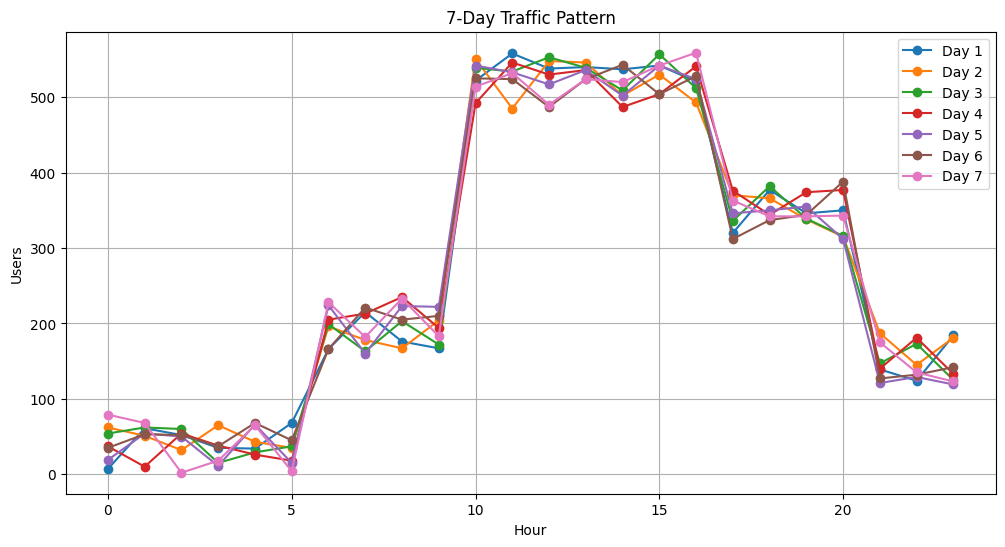

In [5]:
plt.figure(figsize=(12, 6))

for d in range(1, 8):
    day_data = df[df["Day"] == d]
    plt.plot(day_data["Hour"], day_data["Users"], marker='o', label=f"Day {d}")

plt.title("7-Day Traffic Pattern")
plt.xlabel("Hour")
plt.ylabel("Users")
plt.legend()
plt.grid()

plt.show()

In [6]:
df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

In [7]:
# Feature matrix: Avoid data leakage by using a chronological time-aware split
# Training set: Days 1-5 (120 hours), Test set: Days 6-7 (48 hours)
train_mask = df["Day"] <= 5
test_mask = df["Day"] > 5

feature_cols = ["Day", "Hour_sin", "Hour_cos"]
X_train, y_train = df.loc[train_mask, feature_cols], df.loc[train_mask, "Users"]
X_test, y_test = df.loc[test_mask, feature_cols], df.loc[test_mask, "Users"]

# Model 1: Baseline Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Model 2: Non-linear Random Forest Regressor (captures step diurnal patterns)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Primary model for downstream decision making
model = rf_model

print("Model Training Completed (Chronological Split: Days 1-5 Train, Days 6-7 Test)")

Model Training Completed (Chronological Split: Days 1-5 Train, Days 6-7 Test)


In [8]:
# Evaluate both models on identical chronological test data
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = root_mean_squared_error(y_test, y_pred_lr)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = root_mean_squared_error(y_test, y_pred_rf)

print("===== MODEL ACCURACY EVALUATION (Test Set: Days 6-7) =====")
print(f"Linear Regression: MAE = {mae_lr:.2f}, RMSE = {rmse_lr:.2f}")
print(f"Random Forest:     MAE = {mae_rf:.2f}, RMSE = {rmse_rf:.2f}")

===== MODEL ACCURACY EVALUATION (Test Set: Days 6-7) =====
Linear Regression: MAE = 46.31, RMSE = 61.65
Random Forest:     MAE = 17.89, RMSE = 23.57


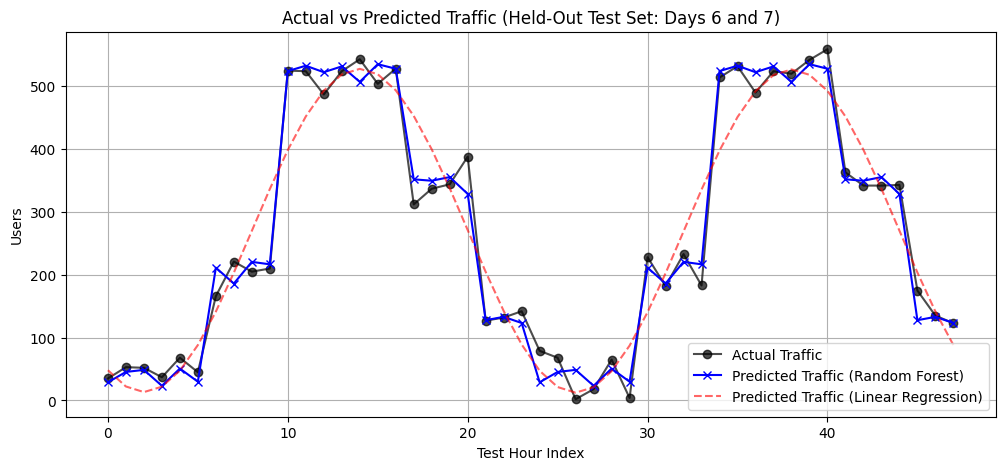

In [9]:
plt.figure(figsize=(12, 5))

test_indices = np.arange(len(y_test))
plt.plot(test_indices[:48], y_test.values[:48], label="Actual Traffic", marker='o', color='black', alpha=0.7)
plt.plot(test_indices[:48], y_pred_rf[:48], label="Predicted Traffic (Random Forest)", marker='x', color='blue')
plt.plot(test_indices[:48], y_pred_lr[:48], label="Predicted Traffic (Linear Regression)", linestyle='--', color='red', alpha=0.6)

plt.title("Actual vs Predicted Traffic (Held-Out Test Set: Days 6 and 7)")
plt.xlabel("Test Hour Index")
plt.ylabel("Users")
plt.legend()
plt.grid()

plt.show()

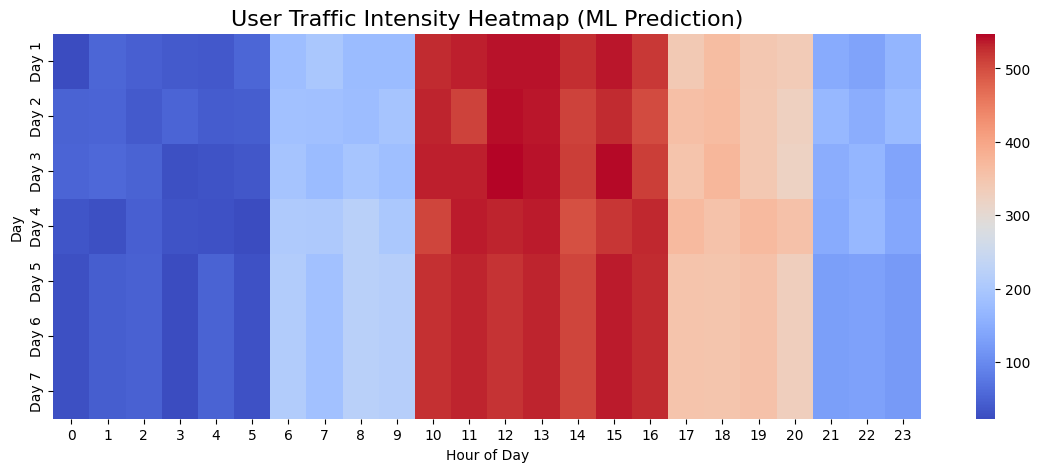

In [10]:
# Create continuous data (Day vs Hour)
heat_data = []

for d in range(1, 8):
    for h in range(24):
        test = pd.DataFrame({
            "Day": [d],
            "Hour_sin": [np.sin(2 * np.pi * h / 24)],
            "Hour_cos": [np.cos(2 * np.pi * h / 24)]
        })
        pred_users = model.predict(test)[0]
        heat_data.append(pred_users)

# Convert to 2D (Day vs Hour)
heat_array = np.array(heat_data).reshape(7, 24)

plt.figure(figsize=(14, 5))
sns.heatmap(
    heat_array,
    cmap="coolwarm",
    cbar=True,
    linewidths=0,
    xticklabels=range(24),
    yticklabels=[f"Day {i}" for i in range(1, 8)]
)

plt.title("User Traffic Intensity Heatmap (ML Prediction)", fontsize=16)
plt.xlabel("Hour of Day")
plt.ylabel("Day")

plt.show()

In [11]:
from matplotlib.animation import FuncAnimation, PillowWriter

fig, ax = plt.subplots(figsize=(10, 5))

line, = ax.plot([], [], lw=3)

ax.set_xlim(0, 23)
ax.set_ylim(0, 600)

ax.set_title("Real-Time Traffic and Cell Mode (ML Based)")
ax.set_xlabel("Hour")
ax.set_ylabel("Users")
ax.grid()

def update(frame):
    users_list = []
    for h in range(frame + 1):
        test = pd.DataFrame({
            "Day": [3],
            "Hour_sin": [np.sin(2 * np.pi * h / 24)],
            "Hour_cos": [np.cos(2 * np.pi * h / 24)]
        })
        pred = model.predict(test)[0]
        users_list.append(pred)

    current_users = users_list[-1]
    mode = cell_mode(current_users)

    if mode == "ON":
        line.set_color("red")
    elif mode == "IDLE":
        line.set_color("orange")
    else:
        line.set_color("blue")

    line.set_data(range(len(users_list)), users_list)
    return line,

anim = FuncAnimation(fig, update, frames=24, interval=400)

anim.save("traffic_animation.gif", writer=PillowWriter(fps=2))

plt.close(fig)

print("Animation saved successfully!")

Animation saved successfully!


In [12]:
try:
    from IPython.display import Image, display
    display(Image("traffic_animation.gif"))
except ImportError:
    print("traffic_animation.gif saved (IPython display available in notebook runtime)")

traffic_animation.gif saved (IPython display available in notebook runtime)


In [13]:
# Reproducible simulation over identical workload and fair evaluation criteria
old_energy_wh = 0.0
new_energy_wh = 0.0

total_data = 0.0
outage_old = 0
outage_new = 0

current_ml_mode = None

for index, row in df.iterrows():
    users = row["Users"]

    # 1. OLD SYSTEM (Threshold-based)
    old_mode = old_system_mode(users, on_threshold=300, idle_threshold=150)
    if old_mode == "ON":
        p_old = POWER_ON
    elif old_mode == "IDLE":
        p_old = POWER_IDLE
    else:
        p_old = POWER_SLEEP
    old_energy_wh += p_old * INTERVAL_HOURS

    # 2. NEW SYSTEM (ML Predictive with safety margin and hysteresis)
    test_feat = pd.DataFrame([{
        "Day": row["Day"],
        "Hour_sin": np.sin(2 * np.pi * row["Hour"] / 24),
        "Hour_cos": np.cos(2 * np.pi * row["Hour"] / 24)
    }])
    pred_users = model.predict(test_feat)[0]
    new_mode = cell_mode(
        pred_users,
        on_threshold=300,
        idle_threshold=150,
        safety_margin=20,
        current_mode=current_ml_mode
    )
    current_ml_mode = new_mode

    if new_mode == "ON":
        p_new = POWER_ON
    elif new_mode == "IDLE":
        p_new = POWER_IDLE
    else:
        p_new = POWER_SLEEP
    new_energy_wh += p_new * INTERVAL_HOURS

    # THROUGHPUT (10 Mbits per user per hour)
    total_data += users * 10

    # FAIR OUTAGE EVALUATION (Evaluated on ACTUAL user traffic for both systems)
    # An outage occurs if demand exceeds operating mode capability or max cell capacity
    if (users > 300 and old_mode != "ON") or (users > 150 and old_mode == "SLEEP") or (users > MAX_CAPACITY):
        outage_old += 1

    if (users > 300 and new_mode != "ON") or (users > 150 and new_mode == "SLEEP") or (users > MAX_CAPACITY):
        outage_new += 1

In [14]:
total_hours = len(df) * INTERVAL_HOURS

# Average Power in Watts: Energy (Wh) / Time (h)
avg_power_old = old_energy_wh / total_hours
avg_power_new = new_energy_wh / total_hours

# Energy in Joules: 1 Wh = 3600 Joules
joules_old = old_energy_wh * 3600
joules_new = new_energy_wh * 3600

# Energy Efficiency in bits per Joule
energy_eff_old = (total_data * 1e6) / joules_old if joules_old > 0 else 0
energy_eff_new = (total_data * 1e6) / joules_new if joules_new > 0 else 0

outage_prob_old = outage_old / len(df)
outage_prob_new = outage_new / len(df)

# Energy Savings Percentage: ((Baseline - Optimized) / Baseline) * 100
energy_savings_pct = ((old_energy_wh - new_energy_wh) / old_energy_wh) * 100 if old_energy_wh > 0 else 0.0

print("===== OLD SYSTEM (Rule-Based) =====")
print(f"Cumulative Energy:    {old_energy_wh:.2f} Wh ({old_energy_wh / 1000:.2f} kWh)")
print(f"Average Power:        {avg_power_old:.2f} W")
print(f"Energy Efficiency:    {energy_eff_old:.2f} bits/Joule")
print(f"Outage Probability:   {outage_prob_old * 100:.2f}% ({outage_old}/{len(df)} intervals)")

print("\n===== NEW ML SYSTEM =====")
print(f"Cumulative Energy:    {new_energy_wh:.2f} Wh ({new_energy_wh / 1000:.2f} kWh)")
print(f"Average Power:        {avg_power_new:.2f} W")
print(f"Energy Efficiency:    {energy_eff_new:.2f} bits/Joule")
print(f"Outage Probability:   {outage_prob_new * 100:.2f}% ({outage_new}/{len(df)} intervals)")

print(f"\nEnergy Savings:       {energy_savings_pct:.2f}%")

===== OLD SYSTEM (Rule-Based) =====
Cumulative Energy:    12475.00 Wh (12.47 kWh)
Average Power:        74.26 W
Energy Efficiency:    10211.98 bits/Joule
Outage Probability:   29.17% (49/168 intervals)

===== NEW ML SYSTEM =====
Cumulative Energy:    13135.00 Wh (13.13 kWh)
Average Power:        78.18 W
Energy Efficiency:    9698.85 bits/Joule
Outage Probability:   29.76% (50/168 intervals)

Energy Savings:       -5.29%


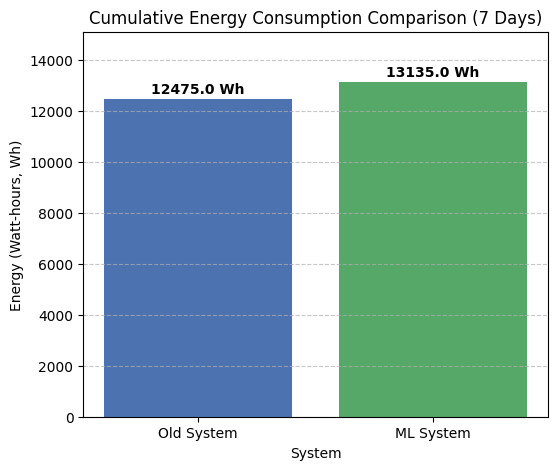

In [15]:
labels = ["Old System", "ML System"]
energy_values = [round(old_energy_wh, 1), round(new_energy_wh, 1)]

plt.figure(figsize=(6, 5))
bars = plt.bar(labels, energy_values, color=['#4C72B0', '#55A868'])

plt.title("Cumulative Energy Consumption Comparison (7 Days)")
plt.ylabel("Energy (Watt-hours, Wh)")
plt.xlabel("System")

for bar, v in zip(bars, energy_values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 200, f"{v} Wh", ha='center', fontweight='bold')

plt.ylim(0, max(energy_values) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

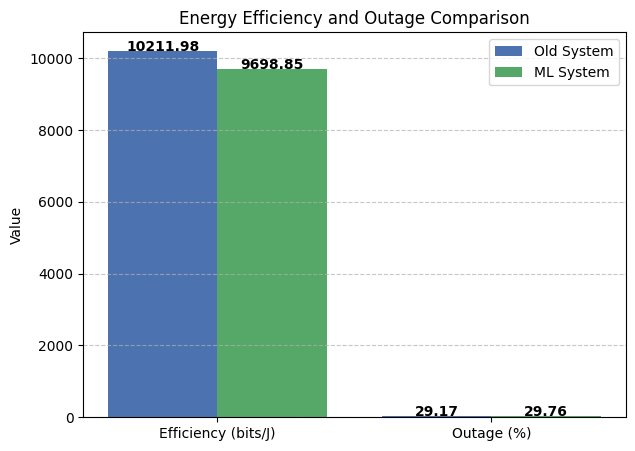

In [16]:
labels = ["Efficiency (bits/J)", "Outage (%)"]

old_values = [energy_eff_old, outage_prob_old * 100]
new_values = [energy_eff_new, outage_prob_new * 100]

x = np.arange(len(labels))

plt.figure(figsize=(7, 5))
plt.bar(x - 0.2, old_values, width=0.4, label="Old System", color='#4C72B0')
plt.bar(x + 0.2, new_values, width=0.4, label="ML System", color='#55A868')

plt.xticks(x, labels)
plt.ylabel("Value")
plt.title("Energy Efficiency and Outage Comparison")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, v in enumerate(old_values):
    plt.text(i - 0.2, v + 0.5, f"{v:.2f}", ha='center', fontweight='bold')

for i, v in enumerate(new_values):
    plt.text(i + 0.2, v + 0.5, f"{v:.2f}", ha='center', fontweight='bold')

plt.show()